# Parte 1: Base, análise exploratória e pré-processamento
**Responsável:** Amabilly · Projeto final de Aprendizado Não Supervisionado (SOM)

**Objetivo desta etapa:** carregar a base *Wholesale Customers*, entender as variáveis, tratar a assimetria
e entregar a matriz `X_scaled` padronizada para o treino do SOM (Roger).

**Base:** 440 clientes de um distribuidor atacadista em Portugal (UCI Machine Learning Repository).
Seis variáveis de gasto anual, em unidades monetárias:

| Variável | Significado |
|---|---|
| `Fresh` | produtos frescos |
| `Milk` | laticínios |
| `Grocery` | mercearia |
| `Frozen` | congelados |
| `Detergents_Paper` | detergentes e papel |
| `Delicassen` | delicatéssen |

Mais duas variáveis categóricas que **não entram no treino** e servem só para validar os resultados:
- `Channel`: 1 = Horeca (hotéis, restaurantes e cafés), 2 = Varejo
- `Region`: 1 = Lisboa, 2 = Porto, 3 = Outras

## 1. Bibliotecas e configuração

In [1]:
import os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

# Paleta do projeto (usar a mesma nas outras partes para manter o padrão visual)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
COR_CANAL = {"Horeca": AZUL, "Varejo": LARANJA}
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#d95926", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.edgecolor": "#888", "axes.labelcolor": "#222", "xtick.color": "#444", "ytick.color": "#444",
})
os.makedirs("figuras", exist_ok=True)
os.makedirs("dados", exist_ok=True)

## 2. Carregamento da base
Se o CSV estiver na pasta `dados/`, ele é lido de lá. Caso contrário (por exemplo, no Colab), é baixado direto da UCI.

In [2]:
CAMINHO = "dados/Wholesale customers data.csv"
URL = "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip"

if not os.path.exists(CAMINHO):
    with urllib.request.urlopen(URL) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall("dados")

df = pd.read_csv(CAMINHO)
GASTOS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
print(df.shape)
df.head()

(440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 3. Qualidade dos dados

In [3]:
print("Tipos:"); print(df.dtypes, "\n")
print("Valores ausentes:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("Valores <= 0 nas variáveis de gasto:", (df[GASTOS] <= 0).sum().sum())

Tipos:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object 

Valores ausentes: 0
Linhas duplicadas: 0
Valores <= 0 nas variáveis de gasto: 0


**Leitura:** a base está limpa. São 440 linhas, sem valores ausentes, sem duplicatas e sem gastos zerados ou negativos,
então não é preciso imputar nem remover nada. Todas as variáveis são inteiras.

## 4. Estatísticas descritivas

In [4]:
desc = df[GASTOS].describe().T
desc["assimetria"] = df[GASTOS].skew()
desc["max/mediana"] = desc["max"] / desc["50%"]
desc.round(1)

,count,mean,std,min,25%,50%,75%,max,assimetria,max/mediana
Fresh,440.0,12000.3,12647.3,3.0,3127.8,8504.0,16933.8,112151.0,2.6,13.2
Milk,440.0,5796.3,7380.4,55.0,1533.0,3627.0,7190.2,73498.0,4.1,20.3
Grocery,440.0,7951.3,9503.2,3.0,2153.0,4755.5,10655.8,92780.0,3.6,19.5
Frozen,440.0,3071.9,4854.7,25.0,742.2,1526.0,3554.2,60869.0,5.9,39.9
Detergents_Paper,440.0,2881.5,4767.9,3.0,256.8,816.5,3922.0,40827.0,3.6,50.0
Delicassen,440.0,1524.9,2820.1,3.0,408.2,965.5,1820.2,47943.0,11.2,49.7


**Leitura:**
- Em todas as variáveis a **média fica bem acima da mediana** (ex.: `Detergents_Paper` tem média ≈ 2.881 e mediana ≈ 816). É sinal de cauda longa à direita.
- O **máximo chega a dezenas de vezes a mediana**: `Delicassen` vai até 47.943, com mediana de 966.
- A assimetria é alta em todas (de 2,6 em `Fresh` a 11,2 em `Delicassen`).
- As escalas são muito diferentes: `Fresh` gira em torno de 12 mil e `Delicassen` em torno de 1,5 mil.

Isso justifica as duas transformações: **log** (para reduzir a assimetria) e **padronização** (para igualar as escalas).
O SOM usa distância euclidiana, então sem esses dois passos as variáveis grandes e os clientes extremos dominariam o mapa.

## 5. Variáveis categóricas (usadas só na validação)

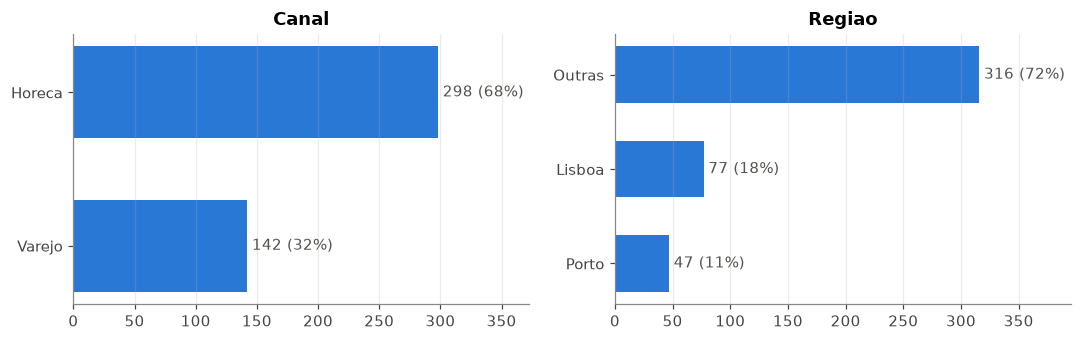

Regiao,Lisboa,Outras,Porto,All
Canal,,,,
Horeca,59,211,28,298
Varejo,18,105,19,142
All,77,316,47,440


In [5]:
df["Canal"] = df["Channel"].map({1: "Horeca", 2: "Varejo"})
df["Regiao"] = df["Region"].map({1: "Lisboa", 2: "Porto", 3: "Outras"})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, col in zip(ax, ["Canal", "Regiao"]):
    vc = df[col].value_counts()
    a.barh(vc.index, vc.values, color=AZUL, height=0.6)
    for i, v in enumerate(vc.values):
        a.text(v + 4, i, f"{v} ({v/len(df):.0%})", va="center", color=CINZA)
    a.set_title(col); a.invert_yaxis(); a.grid(axis="y", visible=False)
    a.set_xlim(0, vc.max() * 1.25)
plt.tight_layout(); plt.savefig("figuras/01_categoricas.png", bbox_inches="tight"); plt.show()

pd.crosstab(df["Canal"], df["Regiao"], margins=True)

**Leitura:** 68% dos clientes são Horeca (298) e 32% são Varejo (142). A maioria está na região "Outras" (316).
Como o `Channel` é desbalanceado, quem for validar o SOM com ele deve olhar proporções, e não só contagens.

## 6. Distribuições originais

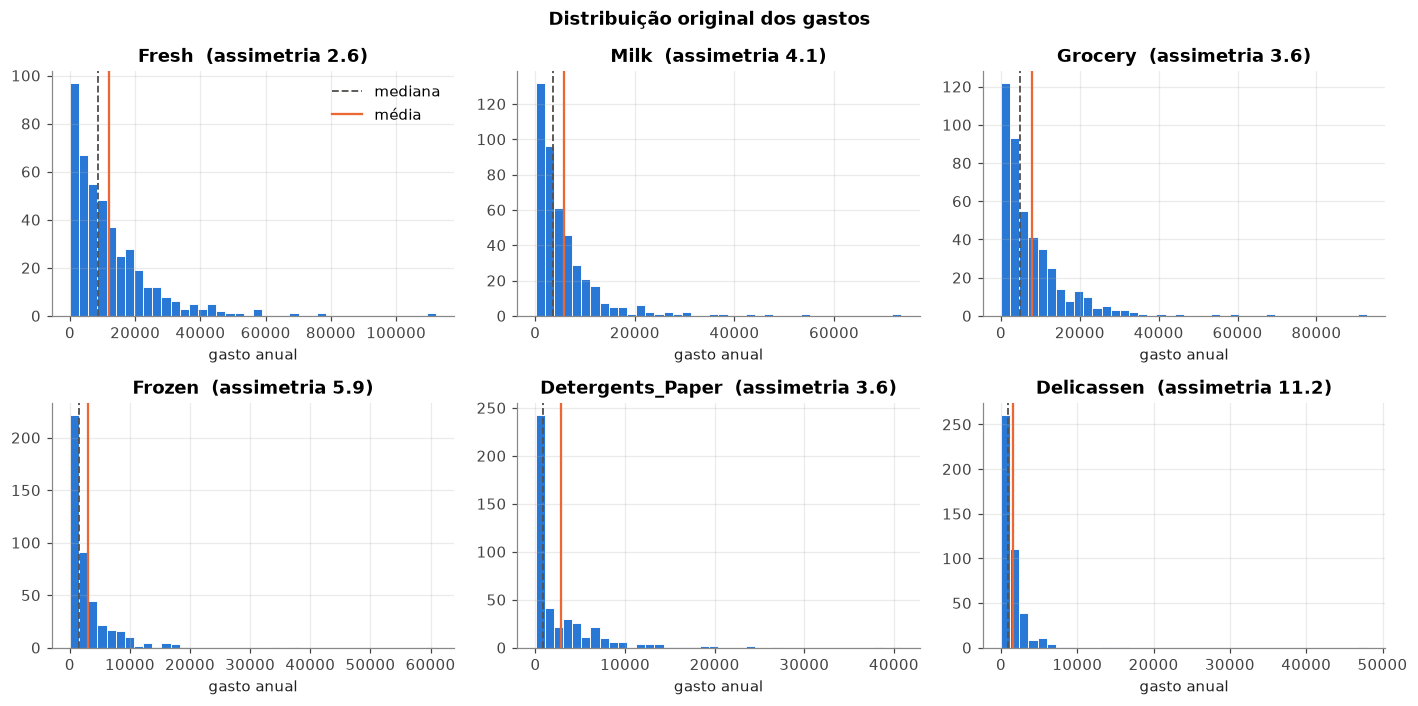

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for a, col in zip(axes.flat, GASTOS):
    a.hist(df[col], bins=40, color=AZUL, edgecolor="white", linewidth=0.6)
    a.axvline(df[col].median(), color=CINZA, ls="--", lw=1.2, label="mediana")
    a.axvline(df[col].mean(), color=LARANJA, lw=1.5, label="média")
    a.set_title(f"{col}  (assimetria {df[col].skew():.1f})"); a.set_xlabel("gasto anual")
axes.flat[0].legend(frameon=False)
fig.suptitle("Distribuição original dos gastos", fontweight="bold")
plt.tight_layout(); plt.savefig("figuras/02_histogramas_original.png", bbox_inches="tight"); plt.show()

**Leitura:** todas as distribuições têm forma de "L", com a maioria dos clientes concentrada em gastos baixos
e alguns poucos com gastos muito altos. A média (laranja) sempre fica à direita da mediana (tracejada).

## 7. Boxplots e outliers (critério IQR)

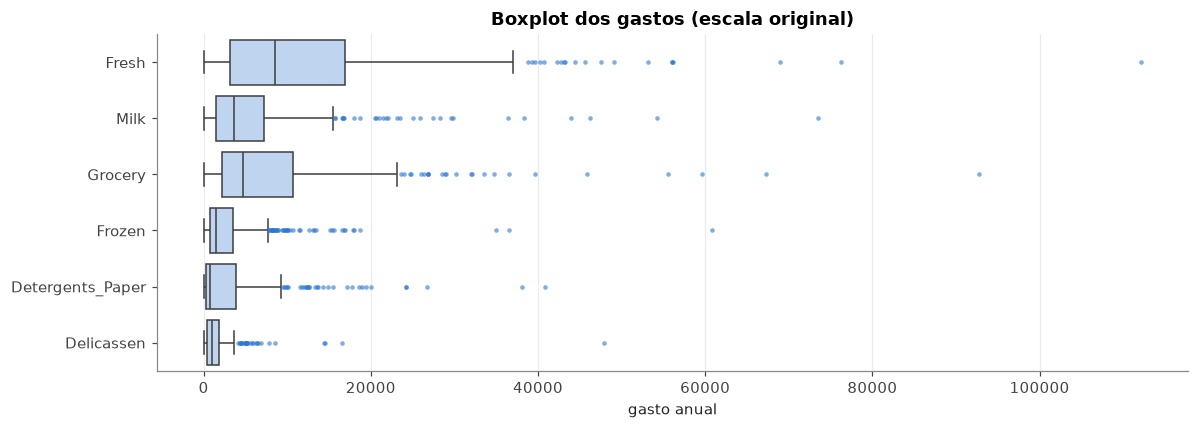

Outliers por variável (escala original):
Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicassen          27

Clientes com pelo menos 1 outlier: 108


In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df[GASTOS], orient="h", color="#b7d3f6", linewidth=1,
            flierprops=dict(marker="o", markersize=3, markerfacecolor=AZUL, markeredgecolor="none", alpha=0.6), ax=ax)
ax.set_title("Boxplot dos gastos (escala original)"); ax.set_xlabel("gasto anual")
plt.tight_layout(); plt.savefig("figuras/03_boxplot_original.png", bbox_inches="tight"); plt.show()

def outliers_iqr(dados):
    q1, q3 = dados.quantile(0.25), dados.quantile(0.75)
    iqr = q3 - q1
    return (dados < q1 - 1.5 * iqr) | (dados > q3 + 1.5 * iqr)

out_orig = outliers_iqr(df[GASTOS])
print("Outliers por variável (escala original):"); print(out_orig.sum().to_string())
print("\nClientes com pelo menos 1 outlier:", out_orig.any(axis=1).sum())

**Leitura:** na escala original, o critério IQR marca dezenas de outliers por variável. Muitos deles, porém,
são só reflexo da assimetria, e não clientes realmente estranhos.

**Decisão: não remover outliers nesta etapa.** Os motivos:
1. Com 440 clientes, cada linha conta.
2. Clientes muito grandes são um perfil real de negócio, não erro de medição.
3. A detecção de outliers é tarefa da análise do SOM (Rafael, pelo erro de quantização individual). Se eu removesse antes, a etapa dele ficaria sem objeto.

O log (próxima seção) já reduz bastante a influência desses pontos.

## 8. Correlação entre as variáveis

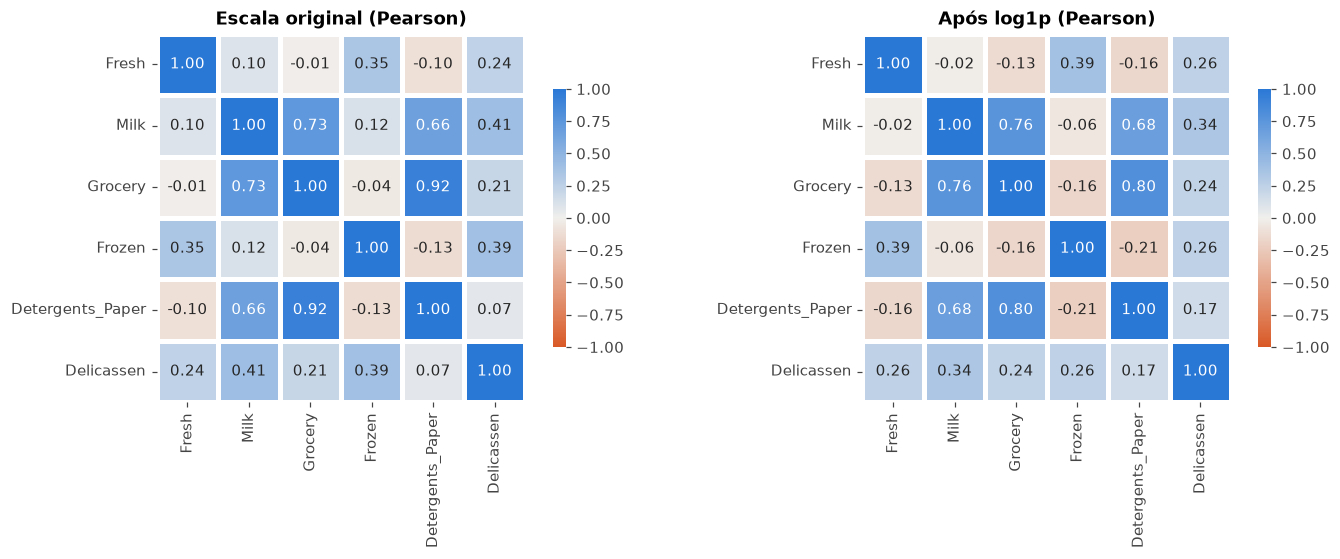

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (dados, titulo) in zip(ax, [(df[GASTOS], "Escala original (Pearson)"),
                                   (np.log1p(df[GASTOS]), "Após log1p (Pearson)")]):
    sns.heatmap(dados.corr(), annot=True, fmt=".2f", cmap=DIVERGENTE, vmin=-1, vmax=1, center=0,
                square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7}, ax=a)
    a.set_title(titulo); a.grid(False)
plt.tight_layout(); plt.savefig("figuras/04_correlacao.png", bbox_inches="tight"); plt.show()

**Leitura:** aparecem dois blocos de produtos:
- **Bloco "varejo / mercearia":** `Grocery` × `Detergents_Paper` (0,92), `Milk` × `Grocery` (0,73) e `Milk` × `Detergents_Paper` (0,66). Esses produtos são comprados juntos.
- **Bloco "Horeca / perecíveis":** `Fresh` × `Frozen` (0,35), mais fraco, com `Delicassen` ligado moderadamente aos dois blocos.
- `Fresh` quase não se correlaciona com `Grocery` e `Detergents_Paper` (perto de 0 ou levemente negativo).

Depois do log, as correlações continuam com a mesma estrutura (`Grocery` × `Detergents_Paper` cai para 0,80
porque deixa de ser puxada pelos clientes extremos). Isso antecipa que o SOM deve separar um eixo
"mercearia/limpeza" de um eixo "frescos/congelados". Essa é a hipótese que o Ruan vai testar nos perfis.

## 9. Gastos por canal (Horeca × Varejo)

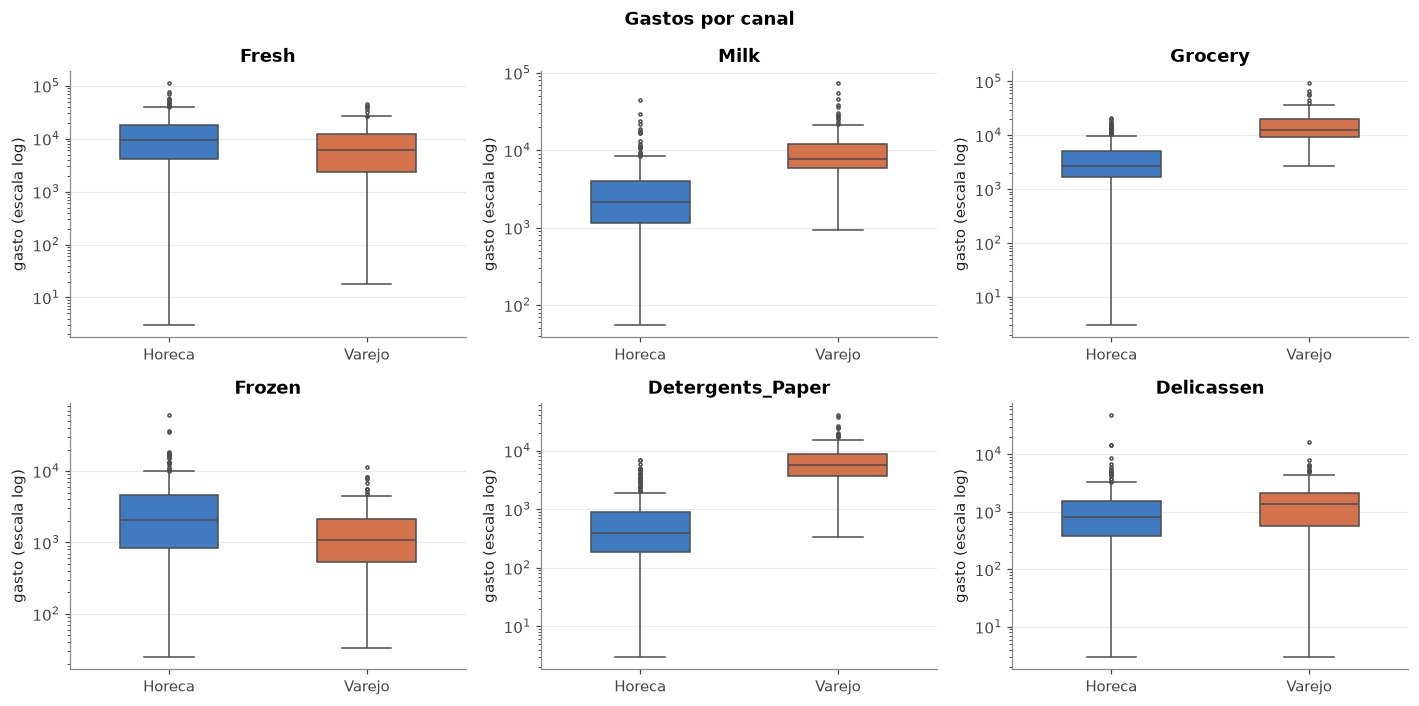

Canal,Horeca,Varejo,razao_Varejo_Horeca
Fresh,9581.5,5993.5,0.63
Milk,2157.0,7812.0,3.62
Grocery,2684.0,12390.0,4.62
Frozen,2057.5,1081.0,0.53
Detergents_Paper,385.5,5614.5,14.56
Delicassen,821.0,1350.0,1.64


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for a, col in zip(axes.flat, GASTOS):
    sns.boxplot(data=df, x="Canal", y=col, hue="Canal", palette=COR_CANAL, order=["Horeca", "Varejo"], legend=False,
                linewidth=1, fliersize=2, width=0.5, ax=a)
    a.set_yscale("log"); a.set_title(col); a.set_xlabel(""); a.set_ylabel("gasto (escala log)")
fig.suptitle("Gastos por canal", fontweight="bold")
plt.tight_layout(); plt.savefig("figuras/05_gastos_por_canal.png", bbox_inches="tight"); plt.show()

df.groupby("Canal")[GASTOS].median().T.assign(razao_Varejo_Horeca=lambda t: (t["Varejo"] / t["Horeca"]).round(2))

**Leitura (medianas):**
- O **Varejo** gasta muito mais em `Grocery` (cerca de 4,6×), `Detergents_Paper` (cerca de 14,6×) e `Milk` (cerca de 3,6×).
- O **Horeca** gasta mais em `Fresh` (cerca de 1,6×) e `Frozen` (cerca de 1,9×).

O `Channel` deve, portanto, aparecer bem separado no SOM, o que é útil para a Erica validar o mapa.

## 10. Transformação logarítmica
Usamos `np.log1p(x) = log(1 + x)`, que é seguro mesmo se algum valor fosse zero.

,assimetria_original,assimetria_log1p
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicassen,11.15,-1.09


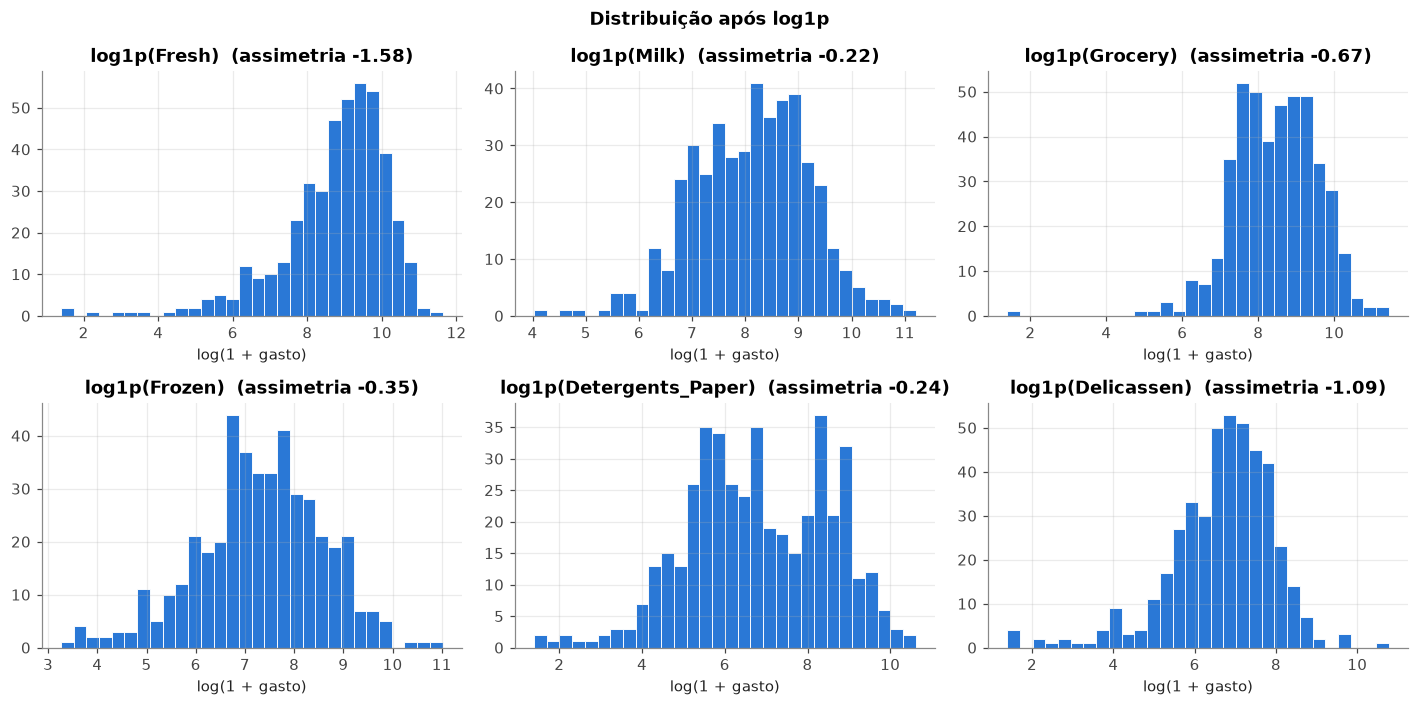

Outliers IQR após log: {'Fresh': 16, 'Milk': 4, 'Grocery': 2, 'Frozen': 10, 'Detergents_Paper': 2, 'Delicassen': 14}
Clientes com pelo menos 1 outlier após log: 42


In [10]:
X_log = np.log1p(df[GASTOS])

comp = pd.DataFrame({"assimetria_original": df[GASTOS].skew(), "assimetria_log1p": X_log.skew()}).round(2)
display(comp)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for a, col in zip(axes.flat, GASTOS):
    a.hist(X_log[col], bins=30, color=AZUL, edgecolor="white", linewidth=0.6)
    a.set_title(f"log1p({col})  (assimetria {X_log[col].skew():.2f})"); a.set_xlabel("log(1 + gasto)")
fig.suptitle("Distribuição após log1p", fontweight="bold")
plt.tight_layout(); plt.savefig("figuras/06_histogramas_log.png", bbox_inches="tight"); plt.show()

out_log = outliers_iqr(X_log)
print("Outliers IQR após log:", out_log.sum().to_dict())
print("Clientes com pelo menos 1 outlier após log:", out_log.any(axis=1).sum())

**Leitura:**
- A assimetria cai de valores entre 2,6 e 11,2 para valores entre −1,6 e −0,2, e as distribuições ficam próximas de uma normal.
- `Fresh` e `Delicassen` ficam com uma pequena cauda à **esquerda**, causada por alguns clientes com gasto quase zero (ex.: valores de 3 a 10 unidades). Eles são candidatos naturais a outliers no SOM.
- O número de outliers IQR cai bastante: os que restam são os casos realmente atípicos, e não efeito da cauda.

## 11. Padronização (`StandardScaler`)
Cada variável fica com média 0 e desvio padrão 1. Assim nenhuma variável domina a distância euclidiana do SOM.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

check = pd.DataFrame(X_scaled, columns=GASTOS).agg(["mean", "std", "min", "max"]).T.round(3)
check

,mean,std,min,max
Fresh,0.0,1.001,-5.001,1.971
Milk,-0.0,1.001,-3.795,2.857
Grocery,-0.0,1.001,-6.355,2.698
Frozen,0.0,1.001,-3.159,2.900
Detergents_Paper,-0.0,1.001,-3.166,2.240
Delicassen,-0.0,1.001,-4.089,3.177


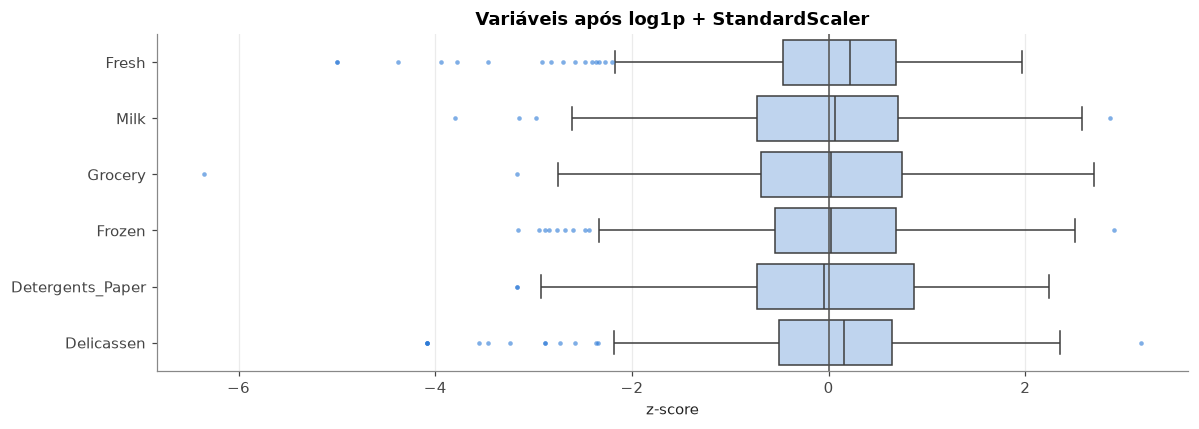

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=pd.DataFrame(X_scaled, columns=GASTOS), orient="h", color="#b7d3f6", linewidth=1,
            flierprops=dict(marker="o", markersize=3, markerfacecolor=AZUL, markeredgecolor="none", alpha=0.6), ax=ax)
ax.axvline(0, color=CINZA, lw=1)
ax.set_title("Variáveis após log1p + StandardScaler"); ax.set_xlabel("z-score")
plt.tight_layout(); plt.savefig("figuras/07_boxplot_padronizado.png", bbox_inches="tight"); plt.show()

**Leitura:** as seis variáveis agora estão na mesma escala (média 0, desvio 1) e com dispersões comparáveis.
Os pontos mais extremos ficam à esquerda (gasto quase nulo em `Fresh`, `Delicassen` e `Detergents_Paper`),
e não mais à direita como na escala original.

## 12. Entrega para o grupo
São salvos dois arquivos em `dados/`:
- `X_scaled.csv`: matriz 440 × 6 padronizada, **entrada do SOM** (Roger) e do K-Means/PCA (Herbe).
- `dados_preprocessados.csv`: base original + `Canal`/`Regiao` em texto + colunas `log_*`. Serve para a validação (Erica) e para os perfis em unidades reais (Ruan).

A ordem das linhas é a mesma da base original (índice 0 a 439), então dá para cruzar tudo pelo índice.

In [13]:
pd.DataFrame(X_scaled, columns=GASTOS).to_csv("dados/X_scaled.csv", index=False)
df.join(X_log.add_prefix("log_")).to_csv("dados/dados_preprocessados.csv", index=False)
print("X_scaled:", X_scaled.shape)

X_scaled: (440, 6)


**Como as outras partes carregam (se estiverem em outro notebook):**
```python
import pandas as pd
X_scaled = pd.read_csv("dados/X_scaled.csv").values          # entrada do SOM
df = pd.read_csv("dados/dados_preprocessados.csv")           # rótulos e valores originais
```
Se estiver no mesmo notebook, as variáveis `X_scaled`, `df`, `GASTOS` e `scaler` já estão na memória.

## 13. Resumo da Parte 1 (para o relatório)
- **Base:** Wholesale Customers, com 440 clientes e 6 variáveis de gasto. Sem ausentes, duplicatas ou valores inválidos.
- **Problema principal:** assimetria forte (de 2,6 a 11,2) e escalas muito diferentes entre as variáveis.
- **Tratamento:** `log1p` reduziu a assimetria para a faixa de −1,6 a −0,2, e o `StandardScaler` deixou as variáveis com média 0 e desvio 1.
- **Outliers:** mantidos de propósito. A identificação fica com o SOM (erro de quantização), e os candidatos são clientes com gasto quase zero em alguma categoria.
- **Estrutura observada:**
  - um bloco correlacionado `Grocery`/`Detergents_Paper`/`Milk`, típico do Varejo;
  - um bloco mais fraco `Fresh`/`Frozen`, típico do Horeca.
- **Validação disponível:** `Channel` separa bem esses blocos. É um bom teste para ver se o SOM encontra estrutura real.